## Reproduction and extension of results from *Slime mould algorithm: A new method for stochastic optimization*

This notebook is meant to reproduce the results from the paper using the mealpy Slime Mould Algorithm (SMA) module. The original paper's results were produced using matlab.

In [4]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mealpy import FloatVar, SMA, GWO, WOA, PSO
from mealpy.evolutionary_based import GA

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler



### Testing Benchmark Functions:

In this section, I perform SMA on three types of functions to test the algorithm's behavior on different problems: 
1. sphere - convergence speed
2. Rastrigin - can it escape local optima?
3. Rosenbrock - test behavior in a narrow valley

I compare SMA's performance to other mealpy algorithms that the paper also used: Grey Wold Optimizer (GWO), Whale Optimization Algorithm (WOA), and Particle Swarm Optimization(PSO). I also used mealpy's developed SMA to test if it in fact improves the algorithm's performance. I used mean, standard deviation, best, and worst across runs along with convergence curves and a Wilcoxon rank-sum test for significance, just like the paper.


### Define Functions:

In [24]:
def make_problem(lower_bound, upper_bound, minmax,objective_function, dim=30):
    return {
        'bounds': FloatVar(lb=(lower_bound,)*dim, ub=(upper_bound,)*dim),
        'minmax': minmax,
        'obj_func': objective_function,
        'log_to':None
    }

def run_models(problem,epoch=1000, pop_size=30, p_t=0.03,n_runs=30):

    algorithms = {
        'SMA': SMA.OriginalSMA(epoch=epoch, pop_size=pop_size, p_t=p_t),
        'DevSMA': SMA.DevSMA(epoch=epoch, pop_size=pop_size, p_t=p_t),
        'GWO': GWO.OriginalGWO(epoch=epoch, pop_size=pop_size),
        'WOA': WOA.OriginalWOA(epoch=epoch, pop_size=pop_size),
        'PSO': PSO.OriginalPSO(epoch=epoch, pop_size=pop_size)
    }

    final_fitness = {name: [] for name in algorithms}
    histories = {name: [] for name in algorithms}

    for name, make_model in algorithms.items():
        for run in range(n_runs):
            model = make_model
            g_best = model.solve(problem, seed=run)
            final_fitness[name].append(g_best.target.fitness)
            histories[name].append(model.history.list_global_best_fit)
        
    rows = []
    for name, vals in final_fitness.items():
        vals = np.array(vals)
        rows.append({
            "Algorithm": name,
            "AVG":vals.mean(),
            "STD":vals.std(),
            'MED':np.median(vals)
        })

    table = pd.DataFrame(rows).set_index("Algorithm")
    return table, final_fitness, histories

In [25]:
#Plot convergence curves
def plot_convergence(histories, title="Convergence Curves",save_path=None):
    fig, ax = plt.subplots(figsize=(10, 6))

    for name, history in histories.items():
        avg_history = np.mean(history, axis=0)
        ax.plot(avg_history, label=name)

    ax.set_yscale('log')
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Best fitness (mean over runs)")
    ax.legend()
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    if save_path:
        fig.savefig(save_path, bbox_inches='tight', dpi=300)

    plt.show()

### Function 1: Sphere (F1)

In [26]:
def sphere_objective_function(solution):
    return np.sum(solution**2)

problem = make_problem(lower_bound=-100, upper_bound=100, minmax="min", objective_function=sphere_objective_function, dim=30)

table, final_fitness, histories = run_models(problem, n_runs=30)
print(table.to_string(float_format=lambda x: f"{x:.3e}"))

/Users/sofieappel/miniconda3/envs/mealpy-env/lib/python3.11/site-packages/mealpy/bio_based/SMA.py:168: RuntimeWarning: invalid value encountered in log10
  np.log10((self.g_best.target.fitness - self.pop[idx].target.fitness) / ss + 1)
/Users/sofieappel/miniconda3/envs/mealpy-env/lib/python3.11/site-packages/mealpy/bio_based/SMA.py:76: RuntimeWarning: invalid value encountered in log10
  np.log10((self.g_best.target.fitness - self.pop[idx].target.fitness) / ss + 1)


                 AVG       STD        MED
Algorithm                                
SMA        0.000e+00 0.000e+00  0.000e+00
DevSMA     0.000e+00 0.000e+00  0.000e+00
GWO        4.591e-65 1.081e-64  8.948e-66
WOA       1.890e-183 0.000e+00 5.308e-192
PSO        8.510e+01 1.436e+02  3.794e+01


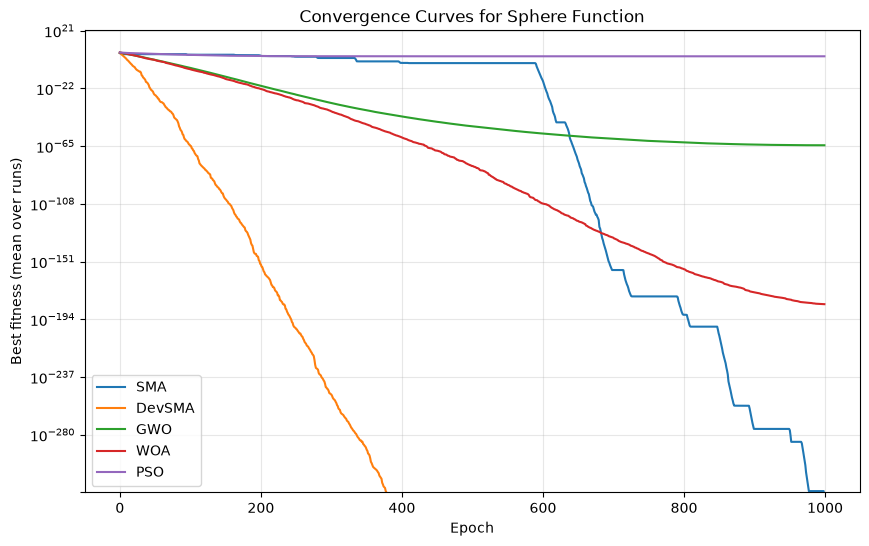

In [27]:
plot_convergence(histories, title="Convergence Curves for Sphere Function", save_path="convergence_curves.png")


## Function 2: Rastrigin (F9)

In [30]:
def rastrigin_objective_function(solution):
    return np.sum(solution**2 - 10 * np.cos(2 * np.pi * solution) + 10)

problem = make_problem(lower_bound=-5.12, upper_bound=5.12, minmax="min", objective_function=rastrigin_objective_function, dim=30)

table, final_fitness, histories = run_models(problem, n_runs=30)
print(table.to_string(float_format=lambda x: f"{x:.3e}"))

/Users/sofieappel/miniconda3/envs/mealpy-env/lib/python3.11/site-packages/mealpy/bio_based/SMA.py:168: RuntimeWarning: invalid value encountered in log10
  np.log10((self.g_best.target.fitness - self.pop[idx].target.fitness) / ss + 1)
/Users/sofieappel/miniconda3/envs/mealpy-env/lib/python3.11/site-packages/mealpy/bio_based/SMA.py:76: RuntimeWarning: invalid value encountered in log10
  np.log10((self.g_best.target.fitness - self.pop[idx].target.fitness) / ss + 1)
/Users/sofieappel/miniconda3/envs/mealpy-env/lib/python3.11/site-packages/mealpy/bio_based/SMA.py:73: RuntimeWarning: invalid value encountered in log10
  np.log10((self.g_best.target.fitness - self.pop[idx].target.fitness) / ss + 1)


                AVG       STD       MED
Algorithm                              
SMA       0.000e+00 0.000e+00 0.000e+00
DevSMA    0.000e+00 0.000e+00 0.000e+00
GWO       1.291e+01 9.410e+00 1.028e+01
WOA       1.098e+02 8.568e+01 1.369e+02
PSO       8.451e+01 1.656e+01 8.312e+01


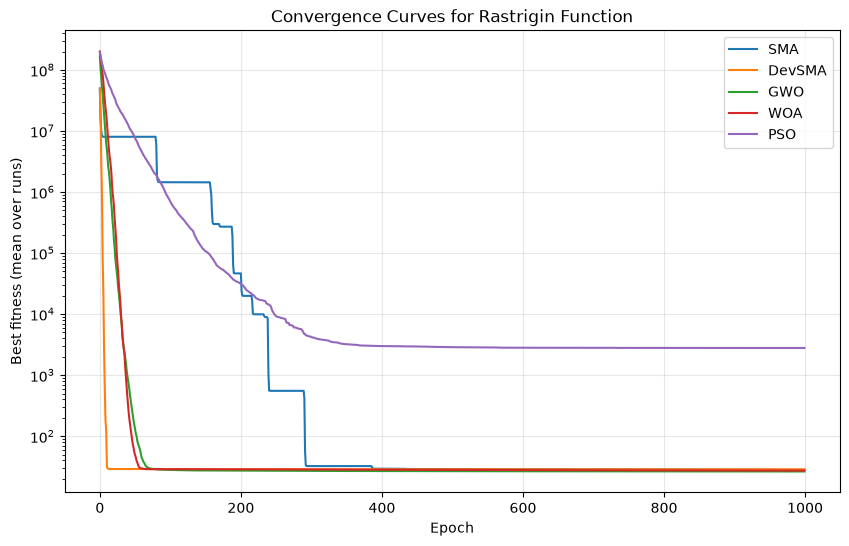

In [34]:
plot_convergence(histories, title="Convergence Curves for Rastrigin Function", save_path="convergence_curve_ragistrin.png")


## Function 3: Rosenbrock (F5)

In [32]:
def rosenbrock_objective_function(solution):
    return np.sum(100 * (solution[1:] - solution[:-1]**2)**2 + (solution[:-1] - 1)**2)

problem = make_problem(lower_bound=-30, upper_bound=30, minmax="min", objective_function=rosenbrock_objective_function, dim=30)

table, final_fitness, histories = run_models(problem, n_runs=30)
print(table.to_string(float_format=lambda x: f"{x:.3e}"))

                AVG       STD       MED
Algorithm                              
SMA       2.805e+01 2.744e-01 2.811e+01
DevSMA    2.869e+01 3.095e-01 2.875e+01
GWO       2.641e+01 8.583e-01 2.616e+01
WOA       2.732e+01 5.957e-01 2.723e+01
PSO       2.787e+03 1.000e+04 3.890e+02


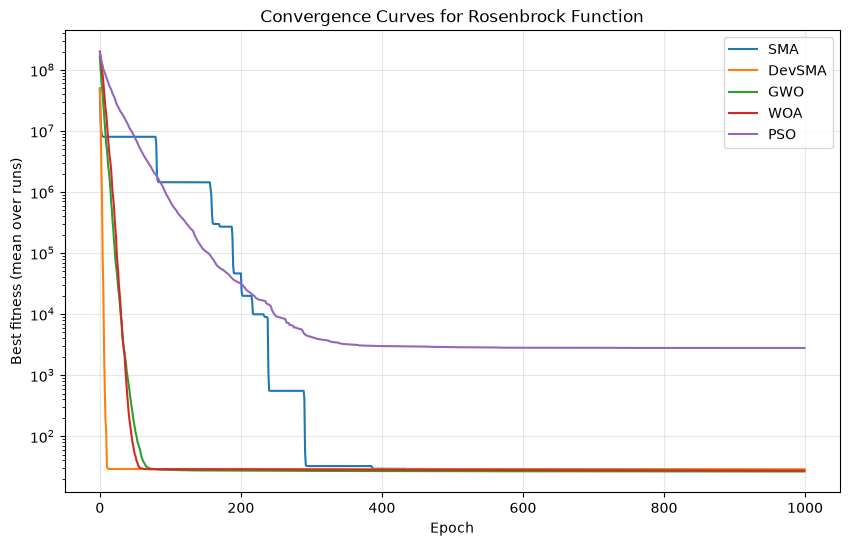

In [33]:
plot_convergence(histories, title="Convergence Curves for Rosenbrock Function", save_path="convergence_curve_rosenbrock.png")


### Apply to machine learning model: hyperparameter tuning

In [3]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def build_model(solution):
    C, gamma = 10**solution[0], 10**solution[1]
    return make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma))

def svm_objective(solution):
    return 1 - cross_val_score(build_model(solution), X_train, y_train, cv=5).mean()

LB, UB = (-3,-4), (3,1)  # Bounds for log10(C) and log10(gamma)

problem = {
    'bounds': FloatVar(lb=LB, ub=UB),
    'minmax': 'min',
    'obj_func': svm_objective,
    'log_to': None
}


In [6]:
#implement random search baseline
def random_search(budget, pop_size, seed):
    rng = np.random.default_rng(seed)
    best_fit, best_sol, history = np.inf, None, []
    for i in range(budget):
        sol = rng.uniform(LB, UB)
        fit = svm_objective(sol)
        if fit < best_fit:
            best_fit, best_sol = fit, sol
        if (i+1) % pop_size == 0:
            history.append(best_fit)
    return best_sol, best_fit,history

In [19]:
def run_ml_experiment(problem, epoch=30,pop_size=20,p_t=0.03,n_runs=30):
    algorithms = {
        'SMA': lambda:SMA.OriginalSMA(epoch=epoch, pop_size=pop_size, p_t=p_t),
        'GWO': lambda: GWO.OriginalGWO(epoch=epoch, pop_size=pop_size),
        'WOA': lambda: WOA.OriginalWOA(epoch=epoch, pop_size=pop_size),
        'PSO': lambda: PSO.OriginalPSO(epoch=epoch, pop_size=pop_size)
    }

    names = list(algorithms)+['Random']
    cv_error = {n: [] for n in names}
    test_acc = {n: [] for n in names}
    histories = {n: [] for n in names}
    best_sol = {n: [] for n in names}

    def record(name, sol, fit, hist):
        cv_error[name].append(fit)
        test_acc[name].append(build_model(sol).fit(X_train, y_train).score(X_test, y_test))
        histories[name].append(hist)
        best_sol[name].append(sol)
        

    for run in range(n_runs):
        for name, make_model in algorithms.items():
            model = make_model()
            g_best = model.solve(problem, seed=run)
            record(name, g_best.solution, g_best.target.fitness,
                   model.history.list_global_best_fit)
        sol, fit, hist = random_search(epoch * pop_size, pop_size, seed=run)
        record("Random", sol, fit, hist)
        print(f"finished run {run + 1}/{n_runs}")

    rows = []
    for n in names:
        e = np.array(cv_error[n])
        rows.append({
            "Algorithm": n,
            "AVG CV error": e.mean(),
            "STD": e.std(ddof=1),
            "MED": np.median(e),
            "Mean test acc": np.mean(test_acc[n])
        })
    table = pd.DataFrame(rows).set_index("Algorithm")
   
    return table, cv_error, test_acc, histories, best_sol

# Start tiny to check it works and time it
table, cv_error, test_acc, histories, best_sol = run_ml_experiment(problem, n_runs=2)
print(table.to_string(float_format=lambda x: f"{x:.4f}"))

finished run 1/2
finished run 2/2
           AVG CV error    STD    MED  Mean test acc
Algorithm                                           
SMA              0.0209 0.0016 0.0209         0.9825
GWO              0.0209 0.0016 0.0209         0.9781
WOA              0.0198 0.0000 0.0198         0.9825
PSO              0.0198 0.0000 0.0198         0.9825
Random           0.0209 0.0016 0.0209         0.9825


In [20]:
for name in cv_error:
    print(name, [np.round(s, 3) for s in best_sol[name]])

SMA [array([ 0.692, -2.082]), array([ 0.275, -1.919])]
GWO [array([ 0.692, -2.082]), array([ 3.   , -3.957])]
WOA [array([ 0.692, -2.082]), array([ 0.888, -2.25 ])]
PSO [array([ 0.692, -2.082]), array([ 0.837, -2.194])]
Random [array([ 0.692, -2.082]), array([ 0.99, -1.72])]


### Apply to feature selection

In [16]:
X, y = fetch_openml('madelon',version=1, return_X_y=True, as_frame=False)
y = np.unique(y, return_inverse=True)[1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y,random_state=42)

#500 features
D = X.shape[1]
#penalty weight on fraction of features used
LAMBDA = 0.01 
#fix folds so every candidate is scored the same way
cv = StratifiedKFold(3, shuffle=True,random_state=0)

THRESH = 0.9

def decode(sol):
    """Continuous vector in [0,1] -> boolean feature mask (feature on if > 0.5)"""
    mask = np.asarray(sol)>THRESH
    if not mask.any():
        mask[np.argmax(sol)]=True
    return mask

def fs_objective(sol):
    """CV error of KNN on selected features and penalty for using many features"""
    mask = decode(sol)
    clf = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5))
    err = 1 - cross_val_score(clf,X_train[:,mask],y_train, cv=cv).mean()
    return err + LAMBDA * mask.mean()

problem = {
    'bounds': FloatVar(lb=(0.,)*D, ub=(1.,)*D),
    'minmax':'min',
    'obj_func':fs_objective,
    'log_to':None
}

In [17]:
# Takes optimized solution and checks performance on test data.
def final_eval(sol):
    mask = decode(sol)
    clf = make_pipeline(StandardScaler(), SVC())
    clf.fit(X_train[:, mask],y_train)
    return clf.score(X_test[:,mask],y_test), int(mask.sum())

def random_search_fs(budget, pop_size, seed):
    """Random masks with varying subset sizes; same evaluation budget as the optimizers."""
    rng = np.random.default_rng(seed)
    best_fit, best_sol, history = np.inf, None, []
    for i in range(budget):
        density = rng.uniform(0.02, 0.5)                      # vary how many features are on
        sol = (rng.uniform(size=D) < density).astype(float)   # 500-long 0/1 vector
        fit = fs_objective(sol)
        if fit < best_fit:
            best_fit, best_sol = fit, sol
        if (i + 1) % pop_size == 0:
            history.append(best_fit)
    return best_sol, best_fit, history

def run_fs(problem, epoch=200, pop_size = 30, n_runs = 30):

    algorithms = {
        'SMA': lambda: SMA.OriginalSMA(epoch, pop_size=pop_size, p_t=0.03),
        'devSMA': lambda: SMA.DevSMA(epoch=epoch, pop_size=pop_size,p_t=0.03),
        'GA': lambda: GA.BaseGA(epoch=epoch, pop_size=pop_size)
    }

    names = list(algorithms) +['Random']
    keys = ['fit','cv_err','n_feat','test_acc','hist','mask']
    res = {n: {k: [] for k in keys} for n in names}

    def record(name, sol, fit, hist):
        mask = decode(sol)
        acc, k = final_eval(sol)
        r = res[name]
        r['fit'].append(fit)
        r['cv_err'].append(fit-LAMBDA*mask.mean())
        r['n_feat'].append(k)
        r['test_acc'].append(acc)
        r['hist'].append(hist)
        r['mask'].append(mask)

    for run in range(n_runs):
        for name, make_model in algorithms.items():
            model = make_model()
            g_best = model.solve(problem, seed=run)
            record(name, g_best.solution, g_best.target.fitness,
                   model.history.list_global_best_fit)
        sol, fit, hist = random_search_fs(epoch * pop_size, pop_size, seed= run +1000)
        record('Random',sol, fit, hist)
        print(f"finished run {run+1}/{n_runs}")

    rows = []
    for n in names:
        r = res[n]
        rows.append({
            'Algorithm':n,
            'Fitness (mean)': np.mean(r['fit']),
            'Fitness (std)': np.std(r['fit'],ddof=1) if n_runs>1 else np.nan,
            'CV error': np.mean(r['cv_err']),
            '# features': np.mean(r['n_feat']),
            'Test acc': np.mean(r['test_acc'])
        })

    return pd.DataFrame(rows).set_index('Algorithm'),res




all_mask = np.ones(D)
acc_all, _ = final_eval(all_mask)
print(f"All {D} features -> SVM test acc {acc_all:.4f}")

import time; t0=time.time()
table, res = run_fs(problem,n_runs=2)
print(f"{time.time()-t0:.0f}s for 2 runs")
print(table.to_string(float_format = lambda x: f"{x:.4f}"))

All 500 features -> SVM test acc 0.5833
finished run 1/2
finished run 2/2
616s for 2 runs
           Fitness (mean)  Fitness (std)  CV error  # features  Test acc
Algorithm                                                               
SMA                0.3855         0.0012    0.3854      2.0000    0.6571
devSMA             0.3800         0.0082    0.3799      2.0000    0.6519
GA                 0.0919         0.0000    0.0918      8.5000    0.8532
Random             0.4104         0.0168    0.4102     12.5000    0.6391


In [18]:
from sklearn.ensemble import RandomForestClassifier

# rank on the training set only, keep the top 50
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0).fit(X_train, y_train)
keep = np.argsort(rf.feature_importances_)[::-1][:50]

X_train_full, X_test_full = X_train, X_test            # keep the originals
X_train, X_test = X_train[:, keep], X_test[:, keep]
D = X_train.shape[1]                                    # now 50

problem = {'bounds': FloatVar(lb=(0.,) * D, ub=(1.,) * D),
           'minmax': 'min', 'obj_func': fs_objective, 'log_to': None}

epoch, pop_size = 100, 30
algorithms = {
    'SMA':    lambda: SMA.OriginalSMA(epoch=epoch, pop_size=pop_size, p_t=0.03),
    'devSMA': lambda: SMA.DevSMA(epoch=epoch, pop_size=pop_size, p_t=0.03),
    'GA':     lambda: GA.BaseGA(epoch=epoch, pop_size=pop_size),
}

table, res = run_fs(problem, epoch=epoch, pop_size=pop_size, n_runs=2)
print(table.to_string(float_format=lambda x: f"{x:.4f}"))

finished run 1/2
finished run 2/2
           Fitness (mean)  Fitness (std)  CV error  # features  Test acc
Algorithm                                                               
SMA                0.1975         0.0031    0.1967      4.0000    0.7699
devSMA             0.2376         0.0199    0.2363      6.5000    0.7564
GA                 0.0937         0.0057    0.0923      7.0000    0.8551
Random             0.1559         0.0301    0.1547      6.0000    0.8173


In [19]:
X_train.shape

(1820, 50)